# Week 7 · Your Law and Its Answer Sheet
**The Evolution of Machine Learning and AI · SETU**

This notebook turns a law of science into something a computer can use, and makes its **answer sheet**: the right answer, worked out another way, that you will test your model against in the coming weeks.

### How to use this notebook (read this first)
- Each grey box is a **cell**. To run a cell, click inside it and press **Shift + Enter** (or click the ▶ button at its left).
- Run the cells **in order, from top to bottom**.
- You only type in cells marked **✏️ YOUR TURN**. Everything else, you just run.
- Text after a `#` is a note for you. The computer ignores it.
- If something goes wrong, click **Runtime → Restart session**, then run the cells again from the top.

| Part | What it does | Who runs it |
|---|---|---|
| Step 0 | Loads the tools | everyone |
| Part 1 | The class example: a sourdough starter | everyone (just run it) |
| Part 2 | **Your law**, if one thing changes over time | most of you |
| Part 3 | **Your law**, if two or three things change each other | only if this is your law's shape |
| Part 4 | **Your law**, if it changes over time and along a line | only if this is your law's shape |

Not sure which part is yours? Look at question 18 on your idea form: *small* → Part 2, *medium* → Part 3, *large* → Part 4.

## Step 0 · Load the tools (run once)

In [1]:
# Step 0: load the tools. Just run this cell. You do not need to change anything.
import numpy as np                      # numbers and lists of numbers
import matplotlib.pyplot as plt         # drawing graphs
from scipy.integrate import solve_ivp   # the "solver": works out the answer in many small steps
print("Ready. Now run the next cell.")

Ready. Now run the next cell.


## Part 1 · The class example: a sourdough starter rising in a jar
**The law in words:** the starter rises fast at first, then slows down as it gets near the top of the jar.

**The law as a sentence:** how fast it rises = r × height × (1 − height ÷ top of jar)

This is the class example. It is *not* one of the project ideas. Run the next two cells and look at the graph.

In [2]:
# ---------- THE CLASS EXAMPLE: a sourdough starter ----------
r     = 0.5     # how fast it grows, per hour        (source: a baking book)
K     = 12.0    # the top of the jar, in cm          (source: I measured the jar)
H0    = 2.0     # the starting height, in cm
t_end = 16.0    # look from 0 to 16 hours

def rate(t, H):                       # how fast the height changes, at time t
    return r * H * (1 - H / K)        # <- THE LAW, as one line of code

def exact(t):                         # the exact formula (this law happens to have one)
    return K / (1 + (K / H0 - 1) * np.exp(-r * t))

print("Class example loaded. Now run the next cell to make its answer sheet.")

Class example loaded. Now run the next cell to make its answer sheet.


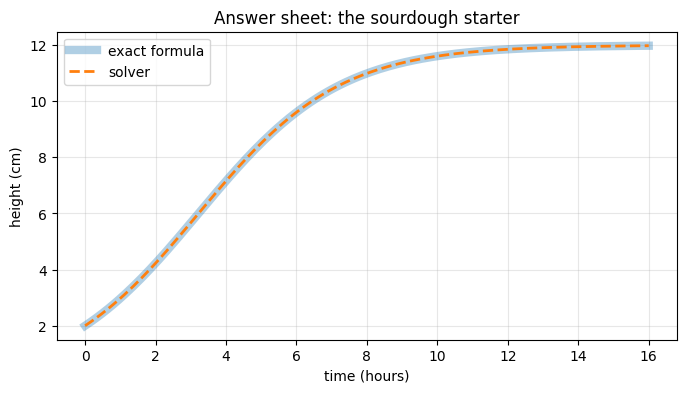

Biggest difference between formula and solver: 0.0 cm
Biggest leftover when the answer is put back into the law: 0.0112


In [3]:
# Make the answer sheet twice: with the exact formula and with the solver. They should agree.
t = np.linspace(0, t_end, 200)                           # 200 moments between 0 and 16 hours
sol = solve_ivp(rate, (0, t_end), [H0], t_eval=t, rtol=1e-8, atol=1e-10)   # the solver, step by step

plt.figure(figsize=(8, 4))
plt.plot(t, exact(t), linewidth=6, alpha=0.35, label="exact formula")
plt.plot(sol.t, sol.y[0], "--", linewidth=2, label="solver")
plt.xlabel("time (hours)"); plt.ylabel("height (cm)")
plt.title("Answer sheet: the sourdough starter"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

print("Biggest difference between formula and solver:", round(float(np.max(np.abs(exact(t) - sol.y[0]))), 6), "cm")

# Week 5's homework check: put the answer back into the law. The leftover should be (almost) zero.
slope = np.gradient(exact(t), t)                 # how fast the exact answer is changing
leftover = slope - rate(t, exact(t))             # the law says this should be zero
print("Biggest leftover when the answer is put back into the law:", round(float(np.max(np.abs(leftover))), 4))

## Part 2 · ✏️ YOUR LAW, if one thing changes over time
Do these steps in the next cell:
1. **Name** what changes, and the unit of time.
2. **Numbers:** give each number a value, and write its unit and where you found it after the `#`.
3. **Start:** the starting value.
4. **How long** to look.
5. **The law:** change the line marked `<- YOUR LAW` so it says *how fast it changes = ...*
6. **Exact formula:** if your law has one (the student guide says so), set `HAS_EXACT = True` and write it in. If not, leave `HAS_EXACT = False`.

The cell below starts with a placeholder law (water draining from a tank through a small hole), so you can see a working example. Replace every line marked `<--` with your own.

In [29]:
# ✏️ YOUR TURN. Change the lines marked <-- . Keep the notes after # up to date.
# The placeholder below is water draining from a tank through a small hole. Replace it with your law.
name      = "temperature (°C)"    # <-- what changes, with its unit, e.g. "temperature (°C)"
time_unit = "minutes"             # <-- your unit of time

start = 55                     # <-- the starting value
t_end = 60                     # <-- how long to look

k = 0.03                       # <-- Cooling Rate, per minute, source: Source: U. H. Kurzweg (2017),"Cooling of a Cup of Coffee", University of Florida, p. 3
T = start                      # <-- Starting coffee temperature, unit:°C, source: Average figure from https://mtpak.coffee/2022/08/takeaway-cups-coffee-temperature-ideal-serving/
Ta = 20                        # <-- Ambient room temperature, unit:°C, source: took average observed in my personal car


def my_rate(t, y):            # how fast it changes, at time t, when the value is y
    return -k * (y - Ta)      # <-- YOUR LAW: Newton’s Law of Cooling says that the hotter an object (coffee in our case) is compared with its surroundings , the faster it cools

HAS_EXACT = True              # <-- True if your law has an exact formula, otherwise False
def my_exact(t):
    return Ta + (T - Ta) * np.exp(-k * t)

print("Your law is loaded. Now run the next cell.")

Your law is loaded. Now run the next cell.


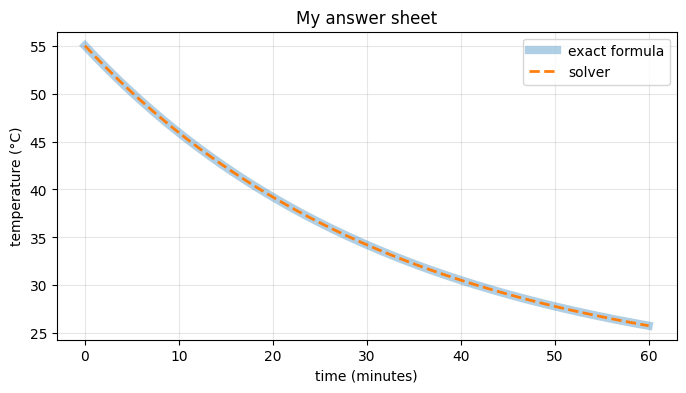

Biggest difference between formula and solver: 0.0
If that number is not close to zero, check your law line and your formula.
Saved as my_answer_sheet.png. To download it: click the folder icon on the left,
then the three dots next to my_answer_sheet.png, then Download.


In [30]:
# Make your answer sheet. Just run this cell.
t = np.linspace(0, t_end, 200)
sol = solve_ivp(my_rate, (0, t_end), [start], t_eval=t, rtol=1e-8, atol=1e-10)

plt.figure(figsize=(8, 4))
if HAS_EXACT:
    plt.plot(t, my_exact(t), linewidth=6, alpha=0.35, label="exact formula")
plt.plot(sol.t, sol.y[0], "--", linewidth=2, label="solver")
plt.xlabel(f"time ({time_unit})"); plt.ylabel(name)
plt.title("My answer sheet"); plt.legend(); plt.grid(alpha=0.3)
plt.savefig("my_answer_sheet.png", dpi=150, bbox_inches="tight")
plt.show()

if HAS_EXACT:
    print("Biggest difference between formula and solver:", round(float(np.max(np.abs(my_exact(t) - sol.y[0]))), 6))
    print("If that number is not close to zero, check your law line and your formula.")
print("Saved as my_answer_sheet.png. To download it: click the folder icon on the left,")
print("then the three dots next to my_answer_sheet.png, then Download.")

## Done
Hand in the Week 7 form on Tutors: your law line, your numbers and where you found them, your starting value, and `my_answer_sheet.png`.